# Visualization QA and UX

Charts are software: they have bugs (wrong numbers, wrong labels, misleading scales) and usability problems (unclear message, unreadable text). **Quality assurance (QA)** for visualisation combines automated checks, data reconciliation tests and short usability tests with real readers.

**After this lesson you can:**

1. Lint charts automatically: titles, labels, legend size, font size, contrast.
2. Reconcile the numbers in a chart with the source data in tests.
3. Run quick usability checks (5-second test, task test).
4. Use a QA checklist before releasing a chart or dashboard.

**Data:** NYC yellow taxi trips, January 2024.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

import matplotlib.colors as mcolors

trips = load_month("2024-01")

## 1. A Chart Linter

A **linter** inspects a finished figure and reports problems. The function below checks rules from Lessons 01 and 03 on any matplotlib figure.

In [2]:
def luminance(c):
    rgb = np.array(mcolors.to_rgb(c))
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    return 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]

def contrast(a, b):
    la, lb = sorted([luminance(a), luminance(b)], reverse=True)
    return (la + 0.05) / (lb + 0.05)

def lint_figure(fig) -> list[str]:
    problems = []
    for i, ax in enumerate(fig.axes):
        tag = f"axes {i}"
        if not any(ax.get_title(loc) for loc in ("left", "center", "right")):
            problems.append(f"{tag}: no title")
        if ax.has_data() and not ax.get_ylabel():
            problems.append(f"{tag}: no y-axis label")
        if ax.has_data() and not ax.get_xlabel():
            problems.append(f"{tag}: no x-axis label")
        legend = ax.get_legend()
        if legend and len(legend.get_texts()) > 7:
            problems.append(f"{tag}: legend with {len(legend.get_texts())} entries (> 7): label directly or group")
        sizes = [t.get_fontsize() for t in ax.get_xticklabels() + ax.get_yticklabels() + [ax.title, ax.xaxis.label, ax.yaxis.label] if t.get_text()]
        if sizes and min(sizes) < 8:
            problems.append(f"{tag}: text smaller than 8 pt ({min(sizes):.0f} pt)")
        bg = ax.get_facecolor()
        colors = {mcolors.to_hex(p.get_facecolor()) for p in ax.patches} | {mcolors.to_hex(l.get_color()) for l in ax.lines}
        for c in colors:
            if contrast(c, bg) < 3:
                problems.append(f"{tag}: colour {c} has contrast {contrast(c, bg):.1f}:1 with the background (< 3:1)")
        if ax.patches and ax.get_ylim()[0] > 0 and any(p.get_height() > 0 for p in ax.patches if hasattr(p, "get_height")):
            problems.append(f"{tag}: bar chart whose y-axis does not start at 0")
    return problems

In [3]:
by_borough = trips.assign(b=trips["PULocationID"].map(zones.set_index("LocationID")["Borough"])).groupby("b").size().drop(
    ["Unknown", "N/A", "EWR"], errors="ignore").sort_values()
by_zone_hour = trips.groupby([trips["tpep_pickup_datetime"].dt.hour, "PULocationID"]).size().unstack()[[132, 138, 161, 162, 230, 186, 236, 237, 142, 239]]

bad, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.bar(by_borough.index, by_borough.values, color="#F0E442")
a1.set_ylim(by_borough.min() * 0.9, by_borough.max() * 1.05)
for z in by_zone_hour.columns:
    a2.plot(by_zone_hour.index, by_zone_hour[z], label=str(z))
a2.legend(fontsize=6)
a2.tick_params(labelsize=6)
plt.close(bad)

good, (b1, b2) = plt.subplots(1, 2, figsize=(12, 3.5))
b1.barh(by_borough.index, by_borough.values, color="#4E79A7")
b1.set(title="Manhattan dominates pickups", xlabel="Trips, January 2024", ylabel="Pickup borough", xscale="log")
top3 = by_zone_hour.sum().nlargest(3).index
for z in by_zone_hour.columns:
    hi = z in top3
    b2.plot(by_zone_hour.index, by_zone_hour[z], color="#4E79A7" if hi else "#767676", lw=2 if hi else 0.8)
b2.set(title="Three busiest zones by hour (others in grey)", xlabel="Hour", ylabel="Trips")
plt.close(good)

for name, fig in [("bad chart", bad), ("good chart", good)]:
    issues = lint_figure(fig)
    print(f"{name}: {len(issues)} problem(s)")
    for i in issues:
        print("   -", i)

bad chart: 14 problem(s)
   - axes 0: no title
   - axes 0: no y-axis label
   - axes 0: no x-axis label
   - axes 0: colour #f0e442 has contrast 1.3:1 with the background (< 3:1)
   - axes 0: bar chart whose y-axis does not start at 0
   - axes 1: no title
   - axes 1: no y-axis label
   - axes 1: no x-axis label
   - axes 1: legend with 10 entries (> 7): label directly or group
   - axes 1: text smaller than 8 pt (6 pt)
   - axes 1: colour #e377c2 has contrast 2.7:1 with the background (< 3:1)
   - axes 1: colour #17becf has contrast 2.3:1 with the background (< 3:1)
   - axes 1: colour #bcbd22 has contrast 2.0:1 with the background (< 3:1)
   - axes 1: colour #ff7f0e has contrast 2.5:1 with the background (< 3:1)
good chart: 0 problem(s)


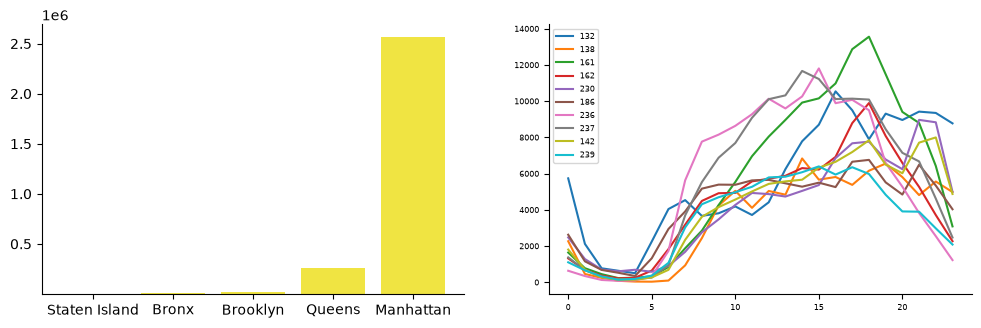

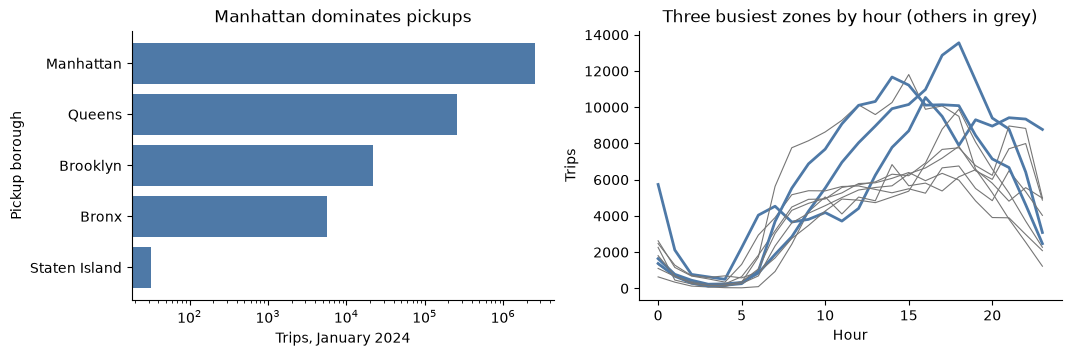

In [4]:
from IPython.display import display

display(bad)
display(good)

The linter cannot judge whether a chart **means** anything, but it reliably catches mechanical problems before a human reviewer spends time on them. It can run in CI on every chart that a report generates (M34).

## 2. Data Reconciliation Tests

A chart is wrong if its numbers do not match the source. A **reconciliation test** recomputes key numbers independently and compares them with the data behind the chart, for example totals, counts and maxima.

In [5]:
def chart_data_daily(df: pd.DataFrame) -> pd.Series:
    """The function that a dashboard uses to build its daily chart."""
    return df.groupby(df["tpep_pickup_datetime"].dt.date)["total_amount"].sum()

def test_daily_chart_reconciles():
    chart = chart_data_daily(trips)
    assert len(chart) == 31, "January must have 31 days"
    assert np.isclose(chart.sum(), trips["total_amount"].sum()), "daily revenue must add up to the monthly total"
    assert chart.min() > 0, "no day may be empty"
    raw = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime"])
    in_month = raw["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left").sum()
    assert len(trips) <= in_month, "cleaning can remove trips but never add them"

def test_bug_is_caught():
    buggy = lambda df: df.groupby(df["tpep_pickup_datetime"].dt.day_of_week)["total_amount"].sum()   # wrong grouping key
    assert len(buggy(trips)) != 31

for test in (test_daily_chart_reconciles, test_bug_is_caught):
    test()
    print(f"{test.__name__}: passed")

test_daily_chart_reconciles: passed
test_bug_is_caught: passed


## 3. Usability Tests

Automated checks do not show whether readers understand a chart. Two quick tests need only a few colleagues:

| Test | Procedure | Pass criterion |
| :--- | :--- | :--- |
| **5-second test** | show the chart for 5 seconds, hide it, ask "what was the main message?" | most testers state the intended message |
| **task test** | ask a concrete question ("which zone had the most trips at 18:00?") and observe | correct answer without help, in a short time |

Five testers find most usability problems of a single chart or dashboard. Write down where they hesitate, misread or ask questions.

## 4. QA Checklist

| Area | Check |
| :--- | :--- |
| data | totals reconcile with the source; filters and date ranges are stated; no silent missing data |
| encoding | appropriate chart type; bars start at 0; consistent scales across panels |
| text | message title; axis labels with units; source and definitions |
| accessibility | contrast ≥ 3:1; colour-blind safe; text ≥ 8–9 pt; alt text |
| interaction | default view answers the main question; filters show their current state |
| performance | dashboard loads in a few seconds; data is pre-aggregated |
| maintenance | owner named; refresh schedule known; tests run automatically |

*Insight: Treat charts like code: lint them automatically, test their numbers against the source, and test their message with real readers. Most chart errors are found by a checklist, not by intuition.*

## Real-World Use Case or Analogy

Visualization QA is like **proofreading and fact-checking a newspaper**: a spell checker catches typos (the linter), a fact-checker verifies every number (reconciliation tests), and a test reader tells you whether the headline is understood (usability test).

Newsrooms such as the Financial Times and The Economist have published corrections for misleading charts; companies have made decisions on dashboards with wrong joins. Automated tests and checklists prevent most of these errors.